# Task 1 — Pergeseran Domain antar Lini Produksi dan Label Noise

**Ruang lingkup.** Bagian ini menjawab butir (e), yaitu pergeseran domain antar lini produksi, dan butir (d), yaitu label noise.

**Model dasar.** Fusi tingkat fitur dengan *modality dropout* 0,3 (selanjutnya disebut A1), yang pada eksperimen sebelumnya memperoleh macro-F1 validasi 0,832. Model ini menurun pada lini B: macro-F1 lini B 0,726 dibanding lini A 0,868. Citra lini B juga lebih gelap (rata-rata intensitas 111,7 dibanding 139,8 pada lini A).

**Pertanyaan yang diuji.**
1. (e) Apakah selisih lini A dan B berkaitan dengan pergeseran domain pada citra, dan apakah normalisasi per lini atau augmentasi kecerahan/kontras mengurangi selisih tersebut?
2. (d) Adakah indikasi label noise pada data latih, dan apakah *label smoothing* meningkatkan ketahanan model?

**Prinsip perbandingan.** Setiap varian hanya mengubah satu faktor terhadap model dasar (R0). Pembagian data, seed, jumlah epoch (15), bobot kelas, dan arsitektur dibuat identik, sehingga perbedaan hasil dapat dikaitkan dengan faktor yang diubah.

| Kode | Normalisasi per lini | Augmentasi kecerahan/kontras | Label smoothing | Tujuan |
|---|---|---|---|---|
| R0 | tidak | tidak | 0 | model dasar (A1) |
| R1 | ya | tidak | 0 | efek normalisasi per lini |
| R2 | tidak | ya | 0 | efek augmentasi |
| R3 | ya | ya | 0 | efek gabungan untuk domain shift |
| R4 | tidak | tidak | 0,1 | efek label smoothing pada data asli |
| R5 | konfigurasi domain terbaik dari R0–R3 | | 0,1 | kandidat model final |
| D | tidak | tidak | 0 | diagnosis: dilatih hanya pada lini A, diuji pada lini B |
| N0, N1 | tidak | tidak | 0 / 0,1 | label latih sengaja diacak 10% untuk menguji label smoothing |

**Alur.** 0 Persiapan → 1 Diagnosis pergeseran domain → 2 Model dasar → 3 Strategi domain → 4 Pelatihan hanya lini A → 5 Deteksi label noise → 6 Label smoothing → 7 Uji dengan noise buatan → 8 Ringkasan dan kesimpulan → 9 Penyimpanan hasil.

## 0. Persiapan lingkungan dan data

Eksperimen dijalankan di Google Colab dengan GPU NVIDIA T4. Kode pada `data.py`, `models.py`, `train_utils.py`, dan `fusion.py` dipakai ulang dari repositori (sudah dijelaskan pada notebook fusi). Berkas baru `robust.py` memuat augmentasi, normalisasi per lini, dan pelatihan dengan label smoothing.

In [1]:
# Cek GPU dan catat versi library
import torch, numpy, pandas, sklearn, sys
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| numpy", numpy.__version__,
      "| pandas", pandas.__version__, "| sklearn", sklearn.__version__)
print("GPU tersedia:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Aktifkan T4 GPU dulu: Runtime -> Change runtime type"

Python 3.13.16 | torch 2.14.1+cu130 | numpy 2.4.6 | pandas 2.2.3 | sklearn 1.6.1
GPU tersedia: True


In [2]:
# Data: unduh dari folder
import os
if not os.path.exists('/content/data/klasifikasi_train.npz'):
    !gdown 10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb -O /content/data_uts_dl.zip
    !mkdir -p /content/data && unzip -q /content/data_uts_dl.zip -d /content/data
!ls /content/data

Downloading...
From (original): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb
From (redirected): https://drive.google.com/uc?id=10lRGd1QRfLJxwdBh1FaItJih-UgO9vpb&confirm=t&uuid=6348467b-a710-41e2-beeb-2f0146f05b97
To: /content/data_uts_dl.zip
100% 396M/396M [00:03<00:00, 105MB/s]
clustering_meta.csv  klasifikasi_test_meta.csv	 klasifikasi_train.npz
clustering.npz	     klasifikasi_test.npz	 rul_test.csv.gz
kamus_data.md	     klasifikasi_train_meta.csv  rul_train.csv.gz


In [3]:
# Repo: clone fork, ambil main terbaru dari repo kelompok, buat branch kerja
from google.colab import userdata
import os
token = userdata.get('GH_TOKEN')
if not os.path.exists('/content/UTSDEEPLEARNING'):
    !git clone https://{token}@github.com/rafiptrnto/UTSDEEPLEARNING.git /content/UTSDEEPLEARNING
%cd /content/UTSDEEPLEARNING
!git config user.name "rafiptrnto"
!git config user.email "rafiputranto665@gmail.com"
!git remote add upstream https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING.git 2>/dev/null || true
!git pull --no-edit upstream main
!git checkout -B task1-domain-noise
!mkdir -p kode/task1_klasifikasi/hasil
!ls kode/task1_klasifikasi

Cloning into '/content/UTSDEEPLEARNING'...
remote: Enumerating objects: 75, done.
remote: Counting objects: 100% (75/75), done.
remote: Compressing objects: 100% (58/58), done.
remote: Total 75 (delta 19), reused 42 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (75/75), 848.58 KiB | 3.93 MiB/s, done.
Resolving deltas: 100% (19/19), done.
/content/UTSDEEPLEARNING
From https://github.com/UTSDEEPLEARNING/UTSDEEPLEARNING
 * branch            main       -> FETCH_HEAD
 * [new branch]      main       -> upstream/main
Already up to date.
Switched to a new branch 'task1-domain-noise'
data.py    hasil      task1_fusi.ipynb	       train_utils.py
fusion.py  models.py  task1_klasifikasi.ipynb


### Kode baru: `robust.py`

- `lini_code`, `lini_stats`: kode numerik lini (A=0, B=1) dan statistik intensitas piksel per lini, dihitung **hanya dari data latih**.
- `augment_img`: augmentasi per citra pada tahap pelatihan saja. Kontras diskalakan terhadap rerata citra dengan faktor acak 0,7–1,3, lalu kecerahan digeser acak dalam rentang ±0,15 (skala piksel 0–1). Rentang ini mencakup selisih rerata intensitas antar lini (sekitar 0,11 pada skala 0–1).
- `prep_img`: normalisasi per lini, yaitu (piksel − rerata lini) / simpangan baku lini.
- `fit3`, `predict3`: pelatihan dan prediksi model fusi dengan opsi augmentasi, normalisasi, dan label smoothing. `fit3` menerima label latih dan label evaluasi terpisah, sehingga label latih dapat dibuat noisy sementara evaluasi tetap memakai label asli.

In [4]:
%%writefile /content/UTSDEEPLEARNING/kode/task1_klasifikasi/robust.py
import numpy as np, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import f1_score
from fusion import drop_sensor

def lini_code(meta):
    return (meta['lini'].values == 'B').astype(np.int64)          # A=0, B=1

def lini_stats(img, lc, idx):
    # rerata dan simpangan baku piksel per lini, hanya dari data latih
    mu = np.zeros(2, np.float32); sd = np.ones(2, np.float32)
    for l in (0, 1):
        v = img[idx[lc[idx] == l]]
        mu[l], sd[l] = float(v.mean()), float(v.std())
    return mu, sd

def augment_img(xi, b_max=0.15, c_rng=(0.7, 1.3)):
    n = xi.shape[0]
    c = torch.empty(n, 1, 1, 1, device=xi.device).uniform_(*c_rng)
    b = torch.empty(n, 1, 1, 1, device=xi.device).uniform_(-b_max, b_max)
    m = xi.mean(dim=(1, 2, 3), keepdim=True)
    return ((xi - m) * c + m + b).clamp(0, 1)

def _norm_to(norm, device):
    if norm is None:
        return None
    return torch.tensor(norm[0], device=device), torch.tensor(norm[1], device=device)

def prep_img(xi, lb, nrm, aug, train):
    if aug and train:
        xi = augment_img(xi)
    if nrm is not None:
        mu, sd = nrm
        xi = (xi - mu[lb].view(-1, 1, 1, 1)) / sd[lb].view(-1, 1, 1, 1)
    return xi

def get_loader3(Xi, Xs, y, lc, idx, bs=256, shuffle=False):
    ds = TensorDataset(torch.from_numpy(Xi[idx]), torch.from_numpy(Xs[idx]),
                       torch.from_numpy(y[idx]).long(), torch.from_numpy(lc[idx]))
    return DataLoader(ds, batch_size=bs, shuffle=shuffle)

@torch.no_grad()
def predict3(model, loader, device, norm=None, sensor_off=False):
    model.eval(); nrm = _norm_to(norm, device); out = []
    for xi, xs, _, lb in loader:
        xi, xs, lb = xi.to(device), xs.to(device), lb.to(device)
        xi = prep_img(xi, lb, nrm, False, False)
        if sensor_off:
            xs = torch.zeros_like(xs)
        out.append(model(xi, xs).softmax(1).cpu())
    return torch.cat(out).numpy()

def fit3(model, Xi, Xs, y, lc, tr_idx, va_idx, epochs=15, lr=1e-3, bs=256, class_weight=None,
         p_drop=0.0, aug=False, norm=None, label_smoothing=0.0, device='cuda', seed=0, y_eval=None):
    torch.manual_seed(seed); np.random.seed(seed)
    y_eval = y if y_eval is None else y_eval
    model.to(device)
    w = None if class_weight is None else torch.tensor(class_weight, dtype=torch.float32, device=device)
    loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=label_smoothing)
    nrm = _norm_to(norm, device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    steps = epochs * int(np.ceil(len(tr_idx) / bs))
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=steps)
    tl = get_loader3(Xi, Xs, y, lc, tr_idx, bs, True)
    vl = get_loader3(Xi, Xs, y_eval, lc, va_idx)
    hist = []
    for ep in range(epochs):
        model.train(); tot = 0.0
        for xi, xs, yb, lb in tl:
            xi, xs, yb, lb = xi.to(device), xs.to(device), yb.to(device), lb.to(device)
            xi = prep_img(xi, lb, nrm, aug, True)
            xs = drop_sensor(xs, p_drop)
            opt.zero_grad()
            loss = loss_fn(model(xi, xs), yb)
            loss.backward(); opt.step(); sched.step()
            tot += loss.item() * len(yb)
        P = predict3(model, vl, device, norm=norm)
        f1 = f1_score(y_eval[va_idx], P.argmax(1), average='macro')
        hist.append((tot / len(tr_idx), f1))
        print(f"ep {ep+1}: loss {hist[-1][0]:.4f} | val macro-F1 {f1:.4f}")
    return hist

Writing /content/UTSDEEPLEARNING/kode/task1_klasifikasi/robust.py


### Pemuatan data dan konfigurasi

Konfigurasi identik dengan notebook fusi: pembagian 80/20 terstratifikasi berdasarkan kelas dan lini (seed 0), statistik sensor dari data latih, kanal *mask* untuk sensor tidak terekam, dan bobot kelas akar dari 1/frekuensi. Hasil setiap model dicatat ke berkas JSON segera setelah model selesai dilatih.

Dua pengaturan dapat dimatikan bila waktu komputasi terbatas: `RUN_DIAGNOSA` (bagian 4) dan `RUN_NOISE_INJECT` (bagian 7).

In [5]:
import sys, json, os
sys.path.append('/content/UTSDEEPLEARNING/kode/task1_klasifikasi')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from sklearn.metrics import f1_score
from IPython.display import Markdown, display
from data import *
from models import *
from train_utils import *
from fusion import *
from robust import *

SEED = 0
EPOCHS = 15
device = 'cuda'
RUN_DIAGNOSA = True        # bagian 4
RUN_NOISE_INJECT = True    # bagian 7

img, sen, meta, y = load('train')
tr_idx, va_idx = make_split(meta, y, seed=SEED)
m, s = sensor_stats(sen[tr_idx])
X_sen = prep_sensor(sen, m, s)
X_img = img[:, None]
lc = lini_code(meta)
yv = y[va_idx]
lini_va = meta['lini'].values[va_idx]
cw = (len(y) / (7 * np.bincount(y))) ** 0.5
mu_l, sd_l = lini_stats(img, lc, tr_idx)

OUT = '/content/UTSDEEPLEARNING/kode/task1_klasifikasi/hasil'
os.makedirs(OUT, exist_ok=True)
HASIL, PRED, INFO = {}, {}, {}

def simpan():
    with open(f'{OUT}/domain_noise_seed0.json', 'w') as f:
        json.dump({'seed': SEED, 'epochs': EPOCHS, 'info': INFO, 'hasil': HASIL}, f, indent=2)

def ringkas(nama, y_true, y_pred, lini):
    per = f1_score(y_true, y_pred, average=None, labels=list(range(7)))
    HASIL[nama] = dict(
        total=float(f1_score(y_true, y_pred, average='macro')),
        A=float(f1_score(y_true[lini == 'A'], y_pred[lini == 'A'], average='macro')),
        B=float(f1_score(y_true[lini == 'B'], y_pred[lini == 'B'], average='macro')),
        per_kelas={k: float(v) for k, v in zip(KELAS, per)})
    h = HASIL[nama]
    print(f"{nama}: macro-F1 {h['total']:.4f} | lini A {h['A']:.4f} | lini B {h['B']:.4f}")
    simpan()

def jalankan(nama, aug=False, norm=False, ls=0.0, tr=None, y_train=None):
    # melatih satu varian model fusi A1 dan mencatat hasilnya pada data validasi yang sama
    tr = tr_idx if tr is None else tr
    yt = y if y_train is None else y_train
    nrm = (mu_l, sd_l) if norm else None
    model = FusionNet()
    fit3(model, X_img, X_sen, yt, lc, tr, va_idx, epochs=EPOCHS, class_weight=cw, p_drop=0.3,
         aug=aug, norm=nrm, label_smoothing=ls, device=device, seed=SEED, y_eval=y)
    P = predict3(model, get_loader3(X_img, X_sen, y, lc, va_idx), device, norm=nrm)
    PRED[nama] = P
    ringkas(nama, yv, P.argmax(1), lini_va)
    del model; torch.cuda.empty_cache()

print("gambar:", X_img.shape, "| sensor:", X_sen.shape, "| latih/valid:", len(tr_idx), len(va_idx))
print("rerata piksel per lini (latih):", dict(zip(['A', 'B'], mu_l.round(3))), "| simpangan baku:", dict(zip(['A', 'B'], sd_l.round(3))))

gambar: (48000, 1, 64, 64) | sensor: (48000, 6, 128) | latih/valid: 38400 9600
rerata piksel per lini (latih): {'A': np.float32(0.548), 'B': np.float32(0.438)} | simpangan baku: {'A': np.float32(0.06), 'B': np.float32(0.075)}


## 1. Diagnosis pergeseran domain

Sebelum menguji perbaikan, kami memeriksa apakah kedua lini memang berbeda secara distribusi. Untuk citra, dibandingkan rerata intensitas dan kontras (simpangan baku piksel) per citra. Untuk sensor, dibandingkan rerata tiap kanal. Pemeriksaan sensor penting karena normalisasi dan augmentasi pada eksperimen ini hanya mengubah citra; bila sensor juga bergeser, perbaikan melalui citra tidak akan menutup seluruh selisih.

rerata_intensitas        kontras       
                  mean    std    mean    std
lini                                        
A                0.548  0.031   0.050  0.009
B                0.438  0.031   0.067  0.010

,suhu,getaran,arus
lini,,,
A,181.119995,0.0,8.473
B,183.115997,0.0,8.416


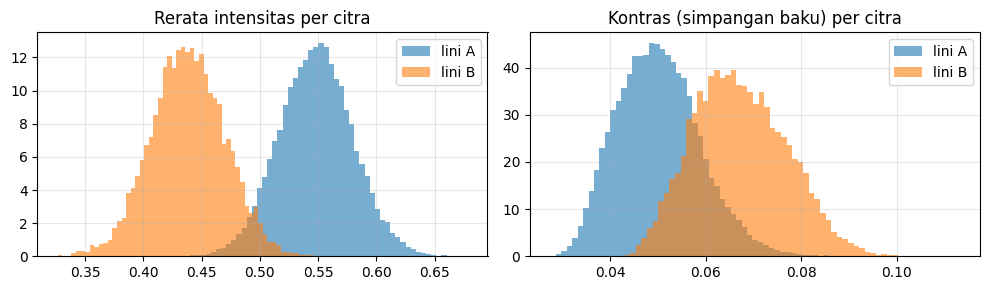

In [6]:
mi = img.reshape(len(img), -1).mean(1)       # rerata intensitas per citra
si = img.reshape(len(img), -1).std(1)        # kontras per citra
tab = pd.DataFrame({'lini': meta['lini'].values, 'rerata_intensitas': mi, 'kontras': si}).groupby('lini').agg(['mean', 'std']).round(3)
display(tab)

kanal = ['suhu', 'getaran', 'arus']
tab_s = pd.DataFrame({l: np.nanmean(sen[meta['lini'].values == l], axis=(0, 2)) for l in ['A', 'B']}, index=kanal).T.round(3)
tab_s.index.name = 'lini'
display(tab_s)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for l, c in [('A', 'C0'), ('B', 'C1')]:
    mk = meta['lini'].values == l
    ax[0].hist(mi[mk], bins=60, alpha=.6, label=f'lini {l}', color=c, density=True)
    ax[1].hist(si[mk], bins=60, alpha=.6, label=f'lini {l}', color=c, density=True)
ax[0].set_title('Rerata intensitas per citra'); ax[1].set_title('Kontras (simpangan baku) per citra')
for a in ax: a.legend(); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 2. Model dasar (R0)

R0 adalah fusi tingkat fitur dengan *modality dropout* 0,3, dilatih ulang pada notebook ini agar seluruh varian dibandingkan di bawah kondisi yang sama persis.

In [7]:
N_R0 = 'R0 Dasar (A1)'
jalankan(N_R0)

ep 1: loss 1.7627 | val macro-F1 0.3414
ep 2: loss 1.2479 | val macro-F1 0.6976
ep 3: loss 0.9732 | val macro-F1 0.7190
ep 4: loss 0.8646 | val macro-F1 0.7031
ep 5: loss 0.7746 | val macro-F1 0.6995
ep 6: loss 0.7055 | val macro-F1 0.8053
ep 7: loss 0.6591 | val macro-F1 0.8020
ep 8: loss 0.6160 | val macro-F1 0.7290
ep 9: loss 0.5713 | val macro-F1 0.8023
ep 10: loss 0.5183 | val macro-F1 0.8230
ep 11: loss 0.4665 | val macro-F1 0.8320
ep 12: loss 0.4157 | val macro-F1 0.8343
ep 13: loss 0.3637 | val macro-F1 0.8354
ep 14: loss 0.3257 | val macro-F1 0.8379
ep 15: loss 0.3034 | val macro-F1 0.8356
R0 Dasar (A1): macro-F1 0.8356 | lini A 0.8734 | lini B 0.7226


## 3. Strategi mengatasi pergeseran domain

Dua pendekatan diuji, masing-masing sendiri dan digabung:
- **R1, normalisasi per lini.** Setiap citra dinormalisasi dengan rerata dan simpangan baku piksel lininya (dari data latih). Pendekatan ini menyamakan skala intensitas kedua lini sebelum masuk jaringan, dan memanfaatkan informasi lini yang tersedia pada metadata data uji.
- **R2, augmentasi kecerahan dan kontras.** Selama pelatihan, kecerahan dan kontras tiap citra diubah acak, sehingga model belajar tidak bergantung pada tingkat kecerahan tertentu. Pendekatan ini tidak memerlukan informasi lini.
- **R3, gabungan keduanya.**

In [8]:
N_R1 = 'R1 + normalisasi per lini'
N_R2 = 'R2 + augmentasi kecerahan/kontras'
N_R3 = 'R3 + normalisasi + augmentasi'
jalankan(N_R1, norm=True)
jalankan(N_R2, aug=True)
jalankan(N_R3, norm=True, aug=True)

ep 1: loss 1.7257 | val macro-F1 0.4593
ep 2: loss 1.2190 | val macro-F1 0.6795
ep 3: loss 0.9796 | val macro-F1 0.7456
ep 4: loss 0.8805 | val macro-F1 0.7209
ep 5: loss 0.7907 | val macro-F1 0.7765
ep 6: loss 0.7234 | val macro-F1 0.7591
ep 7: loss 0.6670 | val macro-F1 0.6407
ep 8: loss 0.6165 | val macro-F1 0.8292
ep 9: loss 0.5651 | val macro-F1 0.8173
ep 10: loss 0.5080 | val macro-F1 0.8082
ep 11: loss 0.4467 | val macro-F1 0.8253
ep 12: loss 0.3869 | val macro-F1 0.8132
ep 13: loss 0.3289 | val macro-F1 0.8155
ep 14: loss 0.2867 | val macro-F1 0.8262
ep 15: loss 0.2656 | val macro-F1 0.8257
R1 + normalisasi per lini: macro-F1 0.8257 | lini A 0.8678 | lini B 0.6976
ep 1: loss 1.8115 | val macro-F1 0.3263
ep 2: loss 1.3737 | val macro-F1 0.6518
ep 3: loss 1.0398 | val macro-F1 0.7263
ep 4: loss 0.9240 | val macro-F1 0.6150
ep 5: loss 0.8330 | val macro-F1 0.7480
ep 6: loss 0.7541 | val macro-F1 0.6653
ep 7: loss 0.7111 | val macro-F1 0.7143
ep 8: loss 0.6514 | val macro-F1 0.7759

In [9]:
R_DOM = [N_R0, N_R1, N_R2, N_R3]
tab = pd.DataFrame(HASIL).T.loc[R_DOM, ['total', 'A', 'B']].astype(float)
tab['selisih A-B'] = tab['A'] - tab['B']
tab.columns = ['macro-F1', 'lini A', 'lini B', 'selisih A-B']
display(tab.round(4))

,macro-F1,lini A,lini B,selisih A-B
R0 Dasar (A1),0.8356,0.8734,0.7226,0.1508
R1 + normalisasi per lini,0.8257,0.8678,0.6976,0.1703
R2 + augmentasi kecerahan/kontras,0.8383,0.8746,0.7269,0.1477
R3 + normalisasi + augmentasi,0.8343,0.8709,0.7222,0.1487


## 4. Diagnosis: pelatihan hanya pada lini A, pengujian pada lini B

Untuk memisahkan pengaruh pergeseran domain dari kesulitan intrinsik lini B, model dilatih hanya dengan data lini A dan diuji pada data validasi kedua lini. Bila macro-F1 pada lini B turun jauh dibanding R0 (yang dilatih pada kedua lini), data lini B pada pelatihan memberi manfaat yang jelas dan pergeseran domain bersifat nyata. Bila turunnya kecil, selisih A–B lebih dipengaruhi kesulitan lini B itu sendiri, misalnya jumlah data yang lebih sedikit (sekitar 25% data).

In [10]:
N_D = 'D Latih lini A saja'
if RUN_DIAGNOSA:
    tr_A = tr_idx[lc[tr_idx] == 0]
    print("jumlah data latih lini A:", len(tr_A), "dari", len(tr_idx))
    jalankan(N_D, tr=tr_A)
else:
    print("RUN_DIAGNOSA = False, bagian ini dilewati.")

jumlah data latih lini A: 28771 dari 38400
ep 1: loss 1.7254 | val macro-F1 0.3464
ep 2: loss 1.1875 | val macro-F1 0.5481
ep 3: loss 0.8919 | val macro-F1 0.5531
ep 4: loss 0.7622 | val macro-F1 0.6324
ep 5: loss 0.6598 | val macro-F1 0.6120
ep 6: loss 0.5823 | val macro-F1 0.6392
ep 7: loss 0.5228 | val macro-F1 0.4619
ep 8: loss 0.4852 | val macro-F1 0.6659
ep 9: loss 0.4371 | val macro-F1 0.6148
ep 10: loss 0.3824 | val macro-F1 0.6683
ep 11: loss 0.3426 | val macro-F1 0.6837
ep 12: loss 0.2956 | val macro-F1 0.6728
ep 13: loss 0.2490 | val macro-F1 0.6757
ep 14: loss 0.2244 | val macro-F1 0.6717
ep 15: loss 0.2127 | val macro-F1 0.6707
D Latih lini A saja: macro-F1 0.6707 | lini A 0.8753 | lini B 0.1286


## 5. Deteksi indikasi label noise

Label noise tidak dapat dipastikan tanpa label sebenarnya. Sebagai indikasi, kami memakai prediksi model R0 pada **data validasi**, yaitu data yang tidak dipakai melatih sehingga model tidak dapat menghafal labelnya. Sampel dengan label tercatat berbeda dari prediksi model yang yakin (probabilitas ≥ 0,9) disebut **kandidat label noise**.

Kandidat ini belum tentu salah label. Model dapat keliru dengan yakin karena pergeseran domain atau kelas yang memang mirip. Karena itu kami memeriksa sebarannya: kandidat yang menumpuk pada satu lini atau satu pasangan kelas lebih mungkin mencerminkan masalah domain atau kemiripan kelas, sedangkan kandidat yang tersebar merata lebih mungkin mencerminkan label yang salah.

In [11]:
P0 = PRED[N_R0]
pred0, conf0 = P0.argmax(1), P0.max(1)
salah = pred0 != yv
kand = salah & (conf0 >= 0.9)

tab = pd.DataFrame({'jumlah': np.bincount(yv, minlength=7),
                    'salah prediksi': np.bincount(yv[salah], minlength=7),
                    'kandidat noise': np.bincount(yv[kand], minlength=7)}, index=KELAS)
tab['kandidat (%)'] = (100 * tab['kandidat noise'] / tab['jumlah']).round(2)
display(tab)

pA = 100 * kand[lini_va == 'A'].mean(); pB = 100 * kand[lini_va == 'B'].mean()
INFO['kandidat'] = dict(persen=float(100 * kand.mean()), A=float(pA), B=float(pB), jumlah=int(kand.sum()), n_valid=int(len(yv)))
print(f"kandidat noise: {kand.sum()} dari {len(yv)} sampel validasi ({100*kand.mean():.2f}%) | lini A {pA:.2f}% | lini B {pB:.2f}%")
print("\nPasangan (label tercatat -> prediksi model) yang paling sering:")
print(pd.Series([f"{KELAS[a]} -> {KELAS[b]}" for a, b in zip(yv[kand], pred0[kand])]).value_counts().head(6).to_string())

,jumlah,salah prediksi,kandidat noise,kandidat (%)
normal,4778,364,61,1.28
gores,1124,336,145,12.90
noda,955,158,72,7.54
retak,721,235,103,14.29
gelembung,686,147,74,10.79
las_dingin,865,71,22,2.54
kontaminasi,471,51,10,2.12


kandidat noise: 487 dari 9600 sampel validasi (5.07%) | lini A 4.62% | lini B 6.44%

Pasangan (label tercatat -> prediksi model) yang paling sering:
gores -> normal        113
retak -> normal         66
noda -> normal          46
gelembung -> normal     38
retak -> gores          37
gelembung -> noda       36


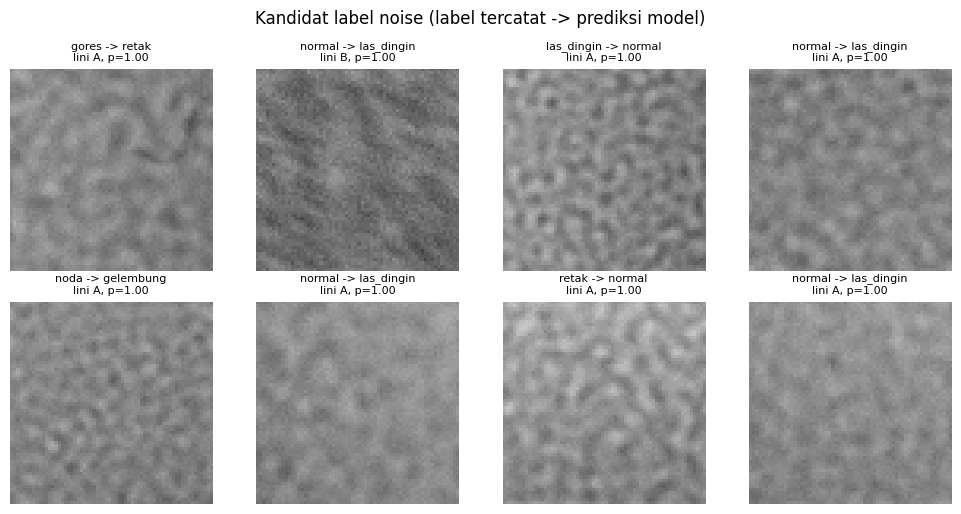

In [12]:
# Contoh citra kandidat dengan keyakinan model tertinggi
urut = np.where(kand)[0]
urut = urut[np.argsort(-conf0[urut])][:8]
if len(urut):
    fig, ax = plt.subplots(2, 4, figsize=(10, 5.2))
    for a, i in zip(ax.ravel(), urut):
        a.imshow(img[va_idx[i]], cmap='gray', vmin=0, vmax=1); a.axis('off')
        a.set_title(f"{KELAS[yv[i]]} -> {KELAS[pred0[i]]}\nlini {lini_va[i]}, p={conf0[i]:.2f}", fontsize=8)
    plt.suptitle('Kandidat label noise (label tercatat -> prediksi model)'); plt.tight_layout(); plt.show()

## 6. Label smoothing

*Label smoothing* mengganti label *one-hot* dengan distribusi yang sedikit melunak (di sini 0,1), sehingga model tidak dipaksa menyamai label dengan keyakinan penuh. Teknik ini murah, tidak mengubah arsitektur, dan membatasi seberapa jauh model menghafal label yang salah. Kami memilihnya dibanding *co-teaching* karena co-teaching memerlukan dua jaringan yang dilatih bersamaan, yang melipatgandakan biaya komputasi.

- **R4:** model dasar dengan label smoothing 0,1.
- **R5:** konfigurasi domain terbaik dari R0–R3 (dipilih otomatis dari macro-F1 total validasi) ditambah label smoothing 0,1. Ini menjadi kandidat model final.

In [13]:
N_R4 = 'R4 + label smoothing 0,1'
N_R5 = 'R5 domain terbaik + label smoothing'
jalankan(N_R4, ls=0.1)

dom = {N_R0: (False, False), N_R1: (True, False), N_R2: (False, True), N_R3: (True, True)}   # (norm, aug)
best_dom = max(dom, key=lambda n: HASIL[n]['total'])
nrm_b, aug_b = dom[best_dom]
INFO['R5_dasar'] = best_dom
print("Konfigurasi domain terbaik untuk R5:", best_dom, "| normalisasi:", nrm_b, "| augmentasi:", aug_b)
jalankan(N_R5, norm=nrm_b, aug=aug_b, ls=0.1)

ep 1: loss 1.8742 | val macro-F1 0.2802
ep 2: loss 1.4914 | val macro-F1 0.6560
ep 3: loss 1.3157 | val macro-F1 0.6878
ep 4: loss 1.2329 | val macro-F1 0.7443
ep 5: loss 1.1653 | val macro-F1 0.7647
ep 6: loss 1.1162 | val macro-F1 0.6840
ep 7: loss 1.0730 | val macro-F1 0.6748
ep 8: loss 1.0378 | val macro-F1 0.8106
ep 9: loss 1.0049 | val macro-F1 0.8222
ep 10: loss 0.9627 | val macro-F1 0.8270
ep 11: loss 0.9237 | val macro-F1 0.8332
ep 12: loss 0.8816 | val macro-F1 0.8363
ep 13: loss 0.8415 | val macro-F1 0.8311
ep 14: loss 0.8150 | val macro-F1 0.8376
ep 15: loss 0.7993 | val macro-F1 0.8348
R4 + label smoothing 0,1: macro-F1 0.8348 | lini A 0.8723 | lini B 0.7224
Konfigurasi domain terbaik untuk R5: R2 + augmentasi kecerahan/kontras | normalisasi: False | augmentasi: True
ep 1: loss 1.9109 | val macro-F1 0.3271
ep 2: loss 1.5816 | val macro-F1 0.6652
ep 3: loss 1.3372 | val macro-F1 0.6749
ep 4: loss 1.2458 | val macro-F1 0.6803
ep 5: loss 1.1790 | val macro-F1 0.7603
ep 6: los

## 7. Uji ketahanan dengan noise buatan

Pada data asli, jumlah label salah tidak diketahui, sehingga manfaat label smoothing sulit dipastikan. Untuk menguji teknik ini dengan kebenaran yang diketahui, 10% label data latih diubah menjadi kelas lain secara acak (noise simetris), sedangkan label validasi tetap asli. Model tanpa smoothing (N0) dibandingkan dengan model dengan smoothing 0,1 (N1), dan keduanya dibandingkan dengan R0 yang dilatih pada label bersih.

In [14]:
N_N0 = 'N0 Noise 10% | tanpa smoothing'
N_N1 = 'N1 Noise 10% | smoothing 0,1'
if RUN_NOISE_INJECT:
    rng = np.random.default_rng(SEED)
    y_noisy = y.copy()
    pilih = rng.choice(tr_idx, size=int(0.10 * len(tr_idx)), replace=False)
    y_noisy[pilih] = (y[pilih] + rng.integers(1, 7, size=len(pilih))) % 7      # selalu kelas berbeda
    print("label latih yang diubah:", len(pilih), "dari", len(tr_idx), "| berbeda dari aslinya:", int((y_noisy[tr_idx] != y[tr_idx]).sum()))
    jalankan(N_N0, y_train=y_noisy)
    jalankan(N_N1, y_train=y_noisy, ls=0.1)
else:
    print("RUN_NOISE_INJECT = False, bagian ini dilewati.")

label latih yang diubah: 3840 dari 38400 | berbeda dari aslinya: 3840
ep 1: loss 1.8343 | val macro-F1 0.2853
ep 2: loss 1.4949 | val macro-F1 0.6367
ep 3: loss 1.3433 | val macro-F1 0.6976
ep 4: loss 1.2673 | val macro-F1 0.6488
ep 5: loss 1.2118 | val macro-F1 0.7514
ep 6: loss 1.1558 | val macro-F1 0.6761
ep 7: loss 1.1142 | val macro-F1 0.6820
ep 8: loss 1.0760 | val macro-F1 0.7987
ep 9: loss 1.0441 | val macro-F1 0.7919
ep 10: loss 0.9881 | val macro-F1 0.7809
ep 11: loss 0.9240 | val macro-F1 0.7951
ep 12: loss 0.8387 | val macro-F1 0.8080
ep 13: loss 0.7304 | val macro-F1 0.7732
ep 14: loss 0.6339 | val macro-F1 0.7814
ep 15: loss 0.5787 | val macro-F1 0.7815
N0 Noise 10% | tanpa smoothing: macro-F1 0.7815 | lini A 0.8228 | lini B 0.6593
ep 1: loss 1.9166 | val macro-F1 0.2698
ep 2: loss 1.6552 | val macro-F1 0.6382
ep 3: loss 1.5339 | val macro-F1 0.7084
ep 4: loss 1.4728 | val macro-F1 0.6541
ep 5: loss 1.4308 | val macro-F1 0.7497
ep 6: loss 1.3842 | val macro-F1 0.7659
ep 7

## 8. Ringkasan dan kesimpulan

Tabel berikut merangkum seluruh varian pada data validasi yang sama. Baris D dilatih hanya dengan lini A, dan baris N0/N1 dilatih dengan label yang sengaja diacak; keduanya adalah eksperimen diagnostik dan bukan kandidat model final.

In [15]:
tab = pd.DataFrame(HASIL).T[['total', 'A', 'B']].astype(float)
tab['selisih A-B'] = tab['A'] - tab['B']
tab.columns = ['macro-F1', 'lini A', 'lini B', 'selisih A-B']
display(tab.round(4))

,macro-F1,lini A,lini B,selisih A-B
R0 Dasar (A1),0.8356,0.8734,0.7226,0.1508
R1 + normalisasi per lini,0.8257,0.8678,0.6976,0.1703
R2 + augmentasi kecerahan/kontras,0.8383,0.8746,0.7269,0.1477
R3 + normalisasi + augmentasi,0.8343,0.8709,0.7222,0.1487
D Latih lini A saja,0.6707,0.8753,0.1286,0.7467
"R4 + label smoothing 0,1",0.8348,0.8723,0.7224,0.1499
R5 domain terbaik + label smoothing,0.8318,0.8676,0.7224,0.1451
N0 Noise 10% | tanpa smoothing,0.7815,0.8228,0.6593,0.1635
"N1 Noise 10% | smoothing 0,1",0.7861,0.8256,0.6673,0.1583


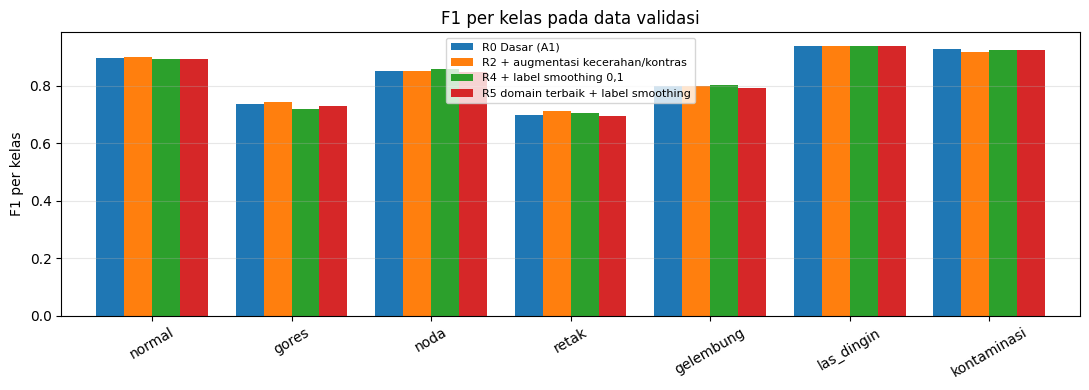

,R0 Dasar (A1),R2 + augmentasi kecerahan/kontras,"R4 + label smoothing 0,1",R5 domain terbaik + label smoothing
normal,0.896,0.900,0.893,0.894
gores,0.735,0.744,0.719,0.729
noda,0.853,0.852,0.859,0.848
retak,0.699,0.714,0.707,0.695
gelembung,0.799,0.801,0.803,0.791
las_dingin,0.939,0.939,0.938,0.939
kontaminasi,0.928,0.918,0.925,0.926


In [16]:
nama_plot = [N_R0, best_dom, N_R4, N_R5]
nama_plot = list(dict.fromkeys(nama_plot))
df = pd.DataFrame({n: HASIL[n]['per_kelas'] for n in nama_plot}).loc[KELAS]
df.plot(kind='bar', figsize=(11, 4), width=0.8)
plt.ylabel('F1 per kelas'); plt.title('F1 per kelas pada data validasi'); plt.xticks(rotation=30)
plt.legend(fontsize=8); plt.grid(axis='y', alpha=.3); plt.tight_layout(); plt.show()
display(df.round(3))

Kesimpulan di bawah disusun otomatis dari hasil di atas, sehingga seluruh angka konsisten dengan tabel.

In [17]:
def _f(x): return f"{x:.3f}".replace('.', ',')
def _d(x): return ('+' if x >= 0 else '−') + f"{abs(x):.3f}".replace('.', ',')
def _p(x): return f"{x:.2f}".replace('.', ',') + '%'

def _arah(d, eps=0.01):
    if d >= eps: return "meningkatkan"
    if d <= -eps: return "menurunkan"
    return "tidak mengubah secara berarti (selisih di bawah 0,01)"

def buat_kesimpulan2(H, info):
    t = []
    R = [N_R0, N_R1, N_R2, N_R3]
    gap = lambda n: H[n]['A'] - H[n]['B']

    # 1. Pergeseran domain
    baris = "; ".join(f"{n}: total {_f(H[n]['total'])}, lini A {_f(H[n]['A'])}, lini B {_f(H[n]['B'])}" for n in R)
    bd = max(R[1:], key=lambda n: H[n]['total'])
    d_tot, d_B = H[bd]['total'] - H[N_R0]['total'], H[bd]['B'] - H[N_R0]['B']
    s = (f"**1. Pergeseran domain antar lini.** {baris}. Di antara varian penanganan domain, macro-F1 total tertinggi dicapai oleh "
         f"**{bd}**, yang {_arah(d_tot)} macro-F1 total ({_d(d_tot)}) dan {_arah(d_B)} macro-F1 lini B ({_d(d_B)}) dibandingkan R0. "
         f"Selisih lini A dan B berubah dari {_f(gap(N_R0))} (R0) menjadi {_f(gap(bd))} ({bd}).")
    if N_D in H:
        dB = H[N_D]['B'] - H[N_R0]['B']
        s += (f" Pada diagnosis, model yang hanya dilatih dengan lini A mencapai macro-F1 {_f(H[N_D]['B'])} pada lini B "
              f"(R0: {_f(H[N_R0]['B'])}, selisih {_d(dB)}) dan {_f(H[N_D]['A'])} pada lini A (R0: {_f(H[N_R0]['A'])}). ")
        s += ("Penurunan pada lini B yang jelas menunjukkan bahwa data lini B pada pelatihan bermanfaat, sehingga pergeseran domain nyata."
              if dB <= -0.02 else
              "Penurunan pada lini B yang kecil menunjukkan bahwa sebagian besar selisih A–B bukan akibat pergeseran domain, "
              "melainkan kesulitan intrinsik lini B atau jumlah datanya yang lebih sedikit.")
    t.append(s)

    # 2. Label noise
    k = info['kandidat']
    s = (f"**2. Indikasi label noise.** Pada data validasi, {_p(k['persen'])} sampel ({k['jumlah']} dari {k['n_valid']}) diprediksi kelas lain oleh R0 dengan "
         f"keyakinan ≥ 0,9 (lini A {_p(k['A'])}, lini B {_p(k['B'])}). ")
    s += ("Kandidat lebih terkonsentrasi pada lini B, yang lebih konsisten dengan kesulitan domain daripada label salah yang tersebar merata. "
          if k['B'] > 1.5 * k['A'] else
          "Kandidat tersebar relatif merata antar lini, sehingga tidak ada indikasi bahwa ia terutama berasal dari satu lini. ")
    s += "Kandidat ini belum dapat dipastikan sebagai label salah karena label sebenarnya tidak tersedia; ia hanya menandai sampel yang layak diperiksa."
    t.append(s)

    # 3. Label smoothing
    d4, d4B = H[N_R4]['total'] - H[N_R0]['total'], H[N_R4]['B'] - H[N_R0]['B']
    s = (f"**3. Label smoothing.** Pada data asli, label smoothing 0,1 {_arah(d4)} macro-F1 total ({_f(H[N_R0]['total'])} → {_f(H[N_R4]['total'])}, {_d(d4)}) "
         f"dan {_arah(d4B)} macro-F1 lini B ({_d(d4B)}).")
    if N_N0 in H and N_N1 in H:
        rusak = H[N_N0]['total'] - H[N_R0]['total']; pulih = H[N_N1]['total'] - H[N_N0]['total']
        s += (f" Pada uji dengan 10% label latih diacak, macro-F1 validasi menjadi {_f(H[N_N0]['total'])} tanpa smoothing ({_d(rusak)} terhadap R0 berlabel bersih) "
              f"dan {_f(H[N_N1]['total'])} dengan smoothing 0,1; smoothing {_arah(pulih)} macro-F1 ({_d(pulih)}) saat noise diketahui ada.")
    t.append(s)

    # 4. Kandidat model final
    kand_final = [N_R0, N_R1, N_R2, N_R3, N_R4, N_R5]
    best = max(kand_final, key=lambda n: H[n]['total'])
    t.append(f"**4. Kandidat model final.** Macro-F1 total tertinggi di antara R0–R5 dicapai oleh **{best}** ({_f(H[best]['total'])}; lini A {_f(H[best]['A'])}, lini B {_f(H[best]['B'])}). "
             f"Konfigurasi domain yang dipakai pada R5 dipilih otomatis: {info['R5_dasar']}.")

    # 5. Keterbatasan
    t.append("**5. Keterbatasan.** Seluruh hasil berasal dari satu seed dan satu pembagian validasi, sehingga selisih kecil (di bawah sekitar 0,01) belum dapat dianggap bermakna. "
             "Konfigurasi terbaik akan dievaluasi ulang dengan tiga seed pada butir (g). Normalisasi dan augmentasi hanya diterapkan pada citra; "
             "pergeseran pada sensor tidak ditangani. Deteksi label noise bersifat indikatif karena tidak ada label sebenarnya.")
    return "\n\n".join(t)

display(Markdown(buat_kesimpulan2(HASIL, INFO)))

**1. Pergeseran domain antar lini.** R0 Dasar (A1): total 0,836, lini A 0,873, lini B 0,723; R1 + normalisasi per lini: total 0,826, lini A 0,868, lini B 0,698; R2 + augmentasi kecerahan/kontras: total 0,838, lini A 0,875, lini B 0,727; R3 + normalisasi + augmentasi: total 0,834, lini A 0,871, lini B 0,722. Di antara varian penanganan domain, macro-F1 total tertinggi dicapai oleh **R2 + augmentasi kecerahan/kontras**, yang tidak mengubah secara berarti (selisih di bawah 0,01) macro-F1 total (+0,003) dan tidak mengubah secara berarti (selisih di bawah 0,01) macro-F1 lini B (+0,004) dibandingkan R0. Selisih lini A dan B berubah dari 0,151 (R0) menjadi 0,148 (R2 + augmentasi kecerahan/kontras). Pada diagnosis, model yang hanya dilatih dengan lini A mencapai macro-F1 0,129 pada lini B (R0: 0,723, selisih −0,594) dan 0,875 pada lini A (R0: 0,873). Penurunan pada lini B yang jelas menunjukkan bahwa data lini B pada pelatihan bermanfaat, sehingga pergeseran domain nyata.

**2. Indikasi label noise.** Pada data validasi, 5,07% sampel (487 dari 9600) diprediksi kelas lain oleh R0 dengan keyakinan ≥ 0,9 (lini A 4,62%, lini B 6,44%). Kandidat tersebar relatif merata antar lini, sehingga tidak ada indikasi bahwa ia terutama berasal dari satu lini. Kandidat ini belum dapat dipastikan sebagai label salah karena label sebenarnya tidak tersedia; ia hanya menandai sampel yang layak diperiksa.

**3. Label smoothing.** Pada data asli, label smoothing 0,1 tidak mengubah secara berarti (selisih di bawah 0,01) macro-F1 total (0,836 → 0,835, −0,001) dan tidak mengubah secara berarti (selisih di bawah 0,01) macro-F1 lini B (−0,000). Pada uji dengan 10% label latih diacak, macro-F1 validasi menjadi 0,782 tanpa smoothing (−0,054 terhadap R0 berlabel bersih) dan 0,786 dengan smoothing 0,1; smoothing tidak mengubah secara berarti (selisih di bawah 0,01) macro-F1 (+0,005) saat noise diketahui ada.

**4. Kandidat model final.** Macro-F1 total tertinggi di antara R0–R5 dicapai oleh **R2 + augmentasi kecerahan/kontras** (0,838; lini A 0,875, lini B 0,727). Konfigurasi domain yang dipakai pada R5 dipilih otomatis: R2 + augmentasi kecerahan/kontras.

**5. Keterbatasan.** Seluruh hasil berasal dari satu seed dan satu pembagian validasi, sehingga selisih kecil (di bawah sekitar 0,01) belum dapat dianggap bermakna. Konfigurasi terbaik akan dievaluasi ulang dengan tiga seed pada butir (g). Normalisasi dan augmentasi hanya diterapkan pada citra; pergeseran pada sensor tidak ditangani. Deteksi label noise bersifat indikatif karena tidak ada label sebenarnya.

## 9. Penyimpanan hasil

Hasil (macro-F1 total, per lini, dan per kelas untuk setiap varian) disimpan dalam `hasil/domain_noise_seed0.json`. Kode di-commit ke repositori kelompok melalui branch `task1-domain-noise`. Bobot model tidak disertakan.

In [18]:
simpan()
print(open(f'{OUT}/domain_noise_seed0.json').read()[:500])

{
  "seed": 0,
  "epochs": 15,
  "info": {
    "kandidat": {
      "persen": 5.072916666666667,
      "A": 4.615598498540248,
      "B": 6.439551308683007,
      "jumlah": 487,
      "n_valid": 9600
    },
    "R5_dasar": "R2 + augmentasi kecerahan/kontras"
  },
  "hasil": {
    "R0 Dasar (A1)": {
      "total": 0.8355632822270519,
      "A": 0.8734171736137567,
      "B": 0.7226209657383448,
      "per_kelas": {
        "normal": 0.8961526748553447,
        "gores": 0.7354176388240784,
        


In [19]:
%cd /content/UTSDEEPLEARNING
!git add kode/task1_klasifikasi/robust.py kode/task1_klasifikasi/hasil/domain_noise_seed0.json
!git commit -m "Task 1: pergeseran domain antar lini dan label noise (normalisasi, augmentasi, label smoothing)"
!git push origin task1-domain-noise

/content/UTSDEEPLEARNING
[task1-domain-noise 5f58210] Task 1: pergeseran domain antar lini dan label noise (normalisasi, augmentasi, label smoothing)
 2 files changed, 223 insertions(+)
 create mode 100644 kode/task1_klasifikasi/hasil/domain_noise_seed0.json
 create mode 100644 kode/task1_klasifikasi/robust.py
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (7/7), done.
Writing objects: 100% (7/7), 3.30 KiB | 3.30 MiB/s, done.
Total 7 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
remote: 
remote: Create a pull request for 'task1-domain-noise' on GitHub by visiting:
remote:      https://github.com/rafiptrnto/UTSDEEPLEARNING/pull/new/task1-domain-noise
remote: 
To https://github.com/rafiptrnto/UTSDEEPLEARNING.git
 * [new branch]      task1-domain-noise -> task1-domain-noise
